In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../Data/queima-e-perda-gn-1000m3.csv', sep=';', decimal=';')

pd.options.display.float_format = '{:,.2f}'.format

df.head()

c:\Users\Pichau\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Users\Pichau\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


,ANO,MÊS,GRANDE REGIÃO,UNIDADE DA FEDERAÇÃO,PRODUTO,LOCALIZAÇÃO,QUEIMADO
0,2000,JAN,REGIÃO NORTE,AMAZONAS,GÁS NATURAL,TERRA,22010
1,2000,FEV,REGIÃO NORTE,AMAZONAS,GÁS NATURAL,TERRA,19473
2,2000,MAR,REGIÃO NORTE,AMAZONAS,GÁS NATURAL,TERRA,9567
3,2000,ABR,REGIÃO NORTE,AMAZONAS,GÁS NATURAL,TERRA,21401
4,2000,MAI,REGIÃO NORTE,AMAZONAS,GÁS NATURAL,TERRA,16468


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6975 entries, 0 to 6974
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   ANO                   6975 non-null   int64
 1   MÊS                   6975 non-null   str  
 2   GRANDE REGIÃO         6975 non-null   str  
 3   UNIDADE DA FEDERAÇÃO  6975 non-null   str  
 4   PRODUTO               6975 non-null   str  
 5   LOCALIZAÇÃO           6975 non-null   str  
 6   QUEIMADO              6975 non-null   str  
dtypes: int64(1), str(6)
memory usage: 716.7 KB


In [3]:
df['QUEIMADO'] = (
    df['QUEIMADO']
    .str.replace(',', '.', regex=False)
    .astype(float)
)

In [4]:
queimado_gn_ano = (
    df[df['ANO'].between(2000, 2025)]
    .groupby('ANO')['QUEIMADO']
    .sum()
    .reset_index()
)

queimado_gn_ano

,ANO,QUEIMADO
0,2000,"2,370,638.92"
1,2001,"2,620,675.83"
2,2002,"2,136,089.56"
3,2003,"1,626,030.12"
4,2004,"1,468,639.00"
5,2005,"2,474,441.60"
6,2006,"1,851,708.23"
7,2007,"1,947,489.06"
8,2008,"2,186,933.63"
9,2009,"3,424,040.41"


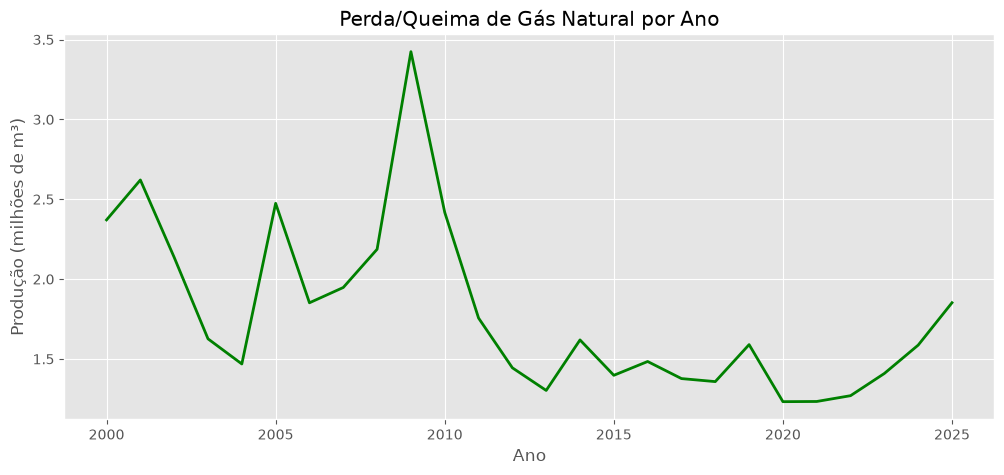

In [5]:
plt.figure(figsize=(12, 5))

plt.style.use('ggplot')

plt.plot(
    queimado_gn_ano['ANO'],
    queimado_gn_ano['QUEIMADO'] / 1e6,
    linewidth=2,
    color='green'
)

plt.title('Perda/Queima de Gás Natural por Ano')
plt.xlabel('Ano')
plt.ylabel('Produção (milhões de m³)');

In [6]:
queimado_gn_local = (
    df[df['ANO'].between(2000, 2025)]
    .groupby('LOCALIZAÇÃO')['QUEIMADO']
    .sum()
    .reset_index()
)

queimado_gn_local

,LOCALIZAÇÃO,QUEIMADO
0,MAR,"39,746,920.89"
1,TERRA,"6,691,642.87"


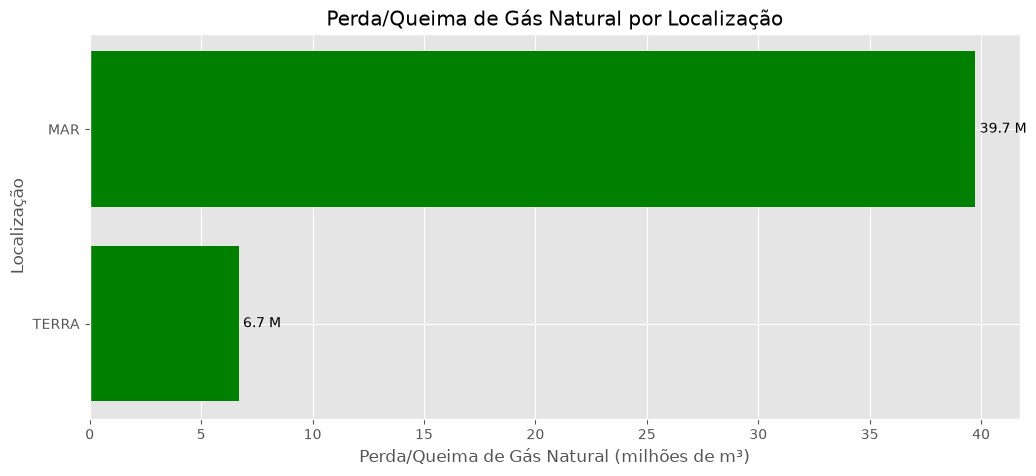

In [7]:
plt.figure(figsize=(12, 5))

plt.style.use('ggplot')

barras = plt.barh(
    queimado_gn_local['LOCALIZAÇÃO'],
    queimado_gn_local['QUEIMADO'] / 1e6,
    color='green'
)

plt.title('Perda/Queima de Gás Natural por Localização')
plt.xlabel('Perda/Queima de Gás Natural (milhões de m³)')
plt.ylabel('Localização')

plt.gca().invert_yaxis()
plt.bar_label(barras, fmt='%.1f M', padding=3);

In [8]:
queima_gn_regiao = (
    df[df['ANO'].between(2000, 2025)]
    .groupby('GRANDE REGIÃO')['QUEIMADO']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

queima_gn_regiao

,GRANDE REGIÃO,QUEIMADO
0,REGIÃO SUDESTE,"38,927,427.83"
1,REGIÃO NORTE,"4,039,212.85"
2,REGIÃO NORDESTE,"3,106,679.94"
3,REGIÃO SUL,"365,243.13"


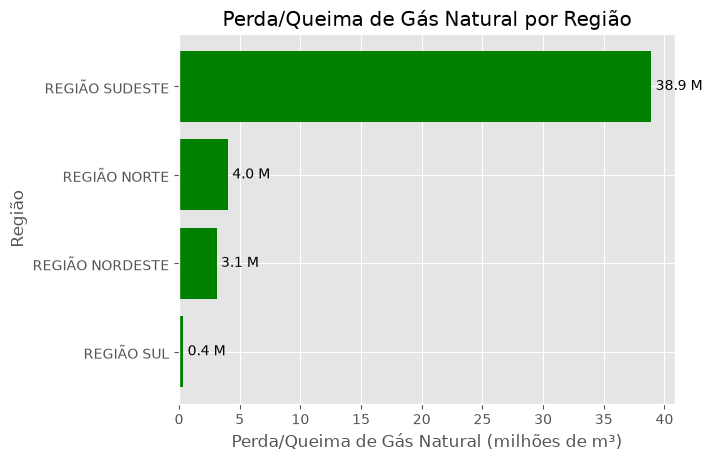

In [9]:
plt.style.use('ggplot')

barras = plt.barh(
    queima_gn_regiao['GRANDE REGIÃO'],
    queima_gn_regiao['QUEIMADO'] / 1e6,
    color='green'
)

plt.title('Perda/Queima de Gás Natural por Região')
plt.xlabel('Perda/Queima de Gás Natural (milhões de m³)')
plt.ylabel('Região')

plt.gca().invert_yaxis()
plt.bar_label(barras, fmt='%.1f M', padding=3);

In [11]:
queima_gn_uf = (
    df.groupby('UNIDADE DA FEDERAÇÃO')['QUEIMADO']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

queima_gn_uf

,UNIDADE DA FEDERAÇÃO,QUEIMADO
0,RIO DE JANEIRO,"34,971,810.53"
1,AMAZONAS,"4,051,774.03"
2,ESPÍRITO SANTO,"3,447,492.17"
3,SÃO PAULO,"1,468,469.90"
4,RIO GRANDE DO NORTE,"1,045,186.13"
5,BAHIA,"898,520.65"
6,SERGIPE,"866,743.53"
7,PARANÁ,"365,543.13"
8,ALAGOAS,"158,503.39"
9,CEARÁ,"121,329.01"


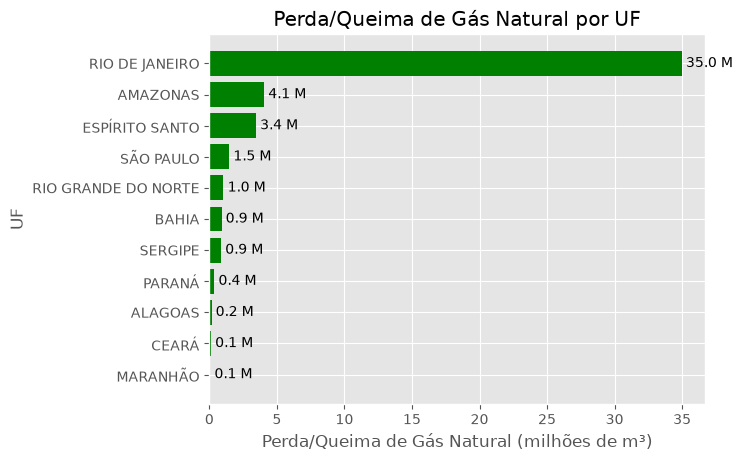

In [12]:
plt.style.use('ggplot')

barras = plt.barh(
    queima_gn_uf['UNIDADE DA FEDERAÇÃO'],
    queima_gn_uf['QUEIMADO'] / 1e6,
    color='green'
)

plt.title('Perda/Queima de Gás Natural por UF')
plt.xlabel('Perda/Queima de Gás Natural (milhões de m³)')
plt.ylabel('UF')

plt.gca().invert_yaxis()
plt.bar_label(barras, fmt='%.1f M', padding=3);

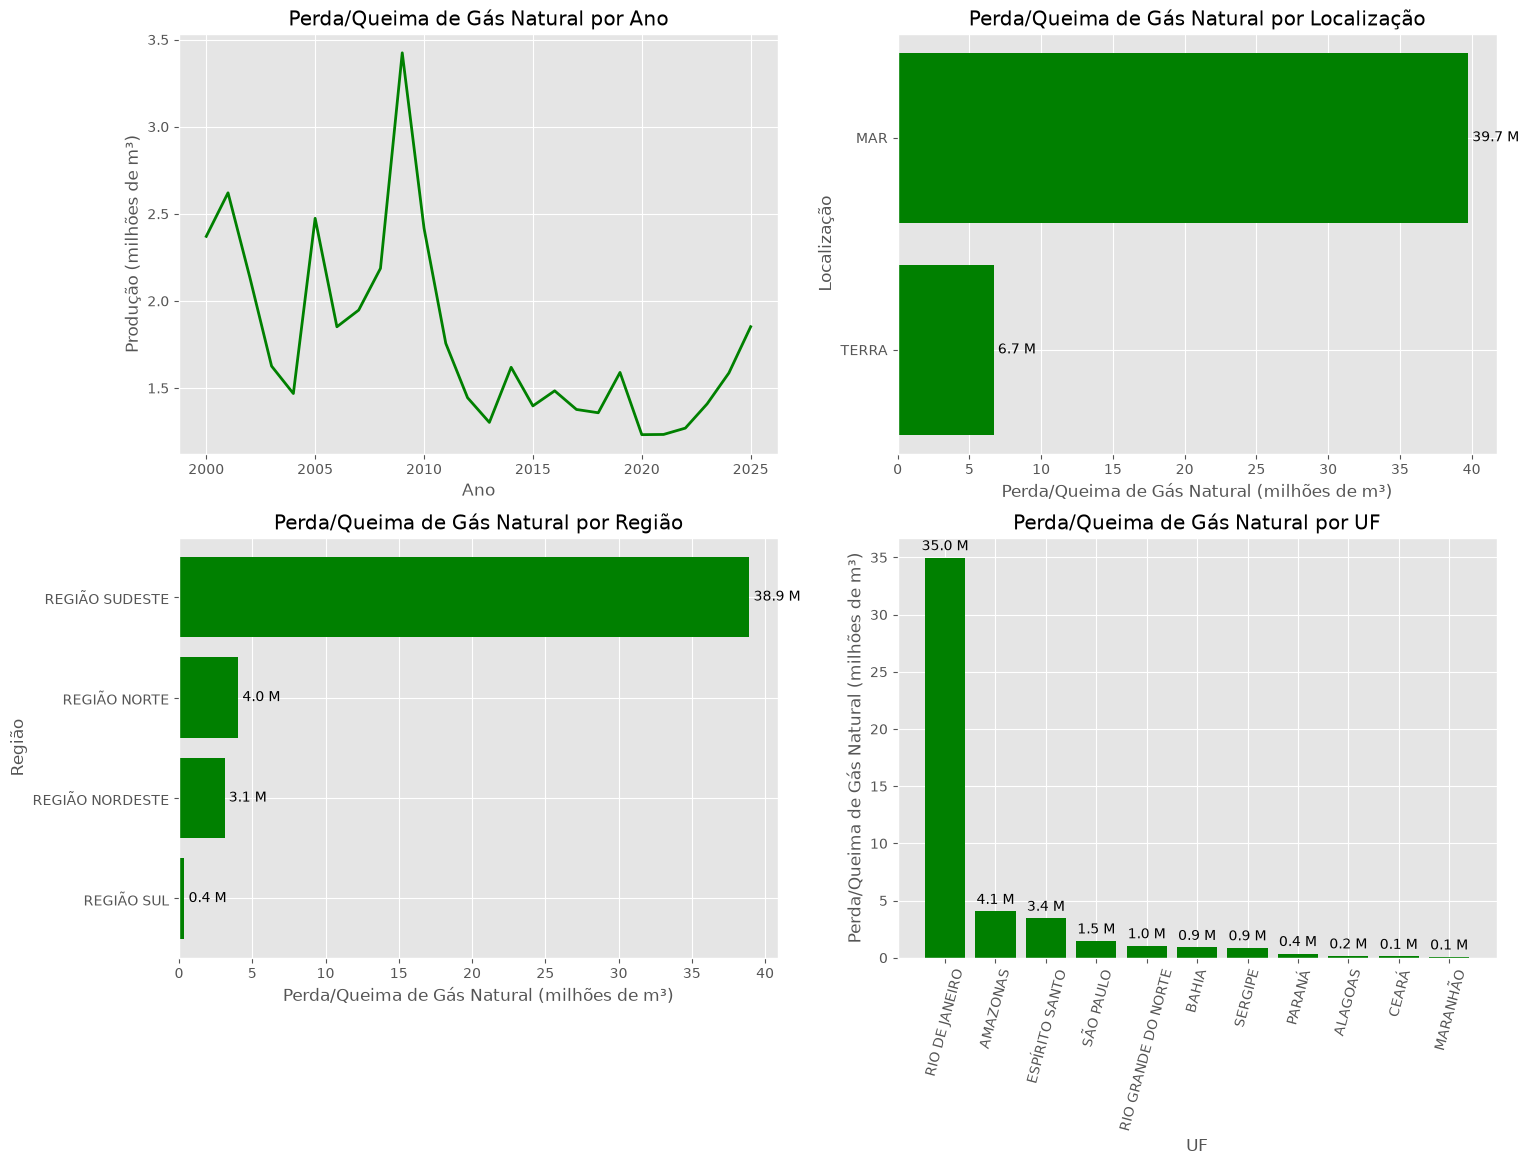

In [32]:
fig, ax = plt.subplots(2, 2, figsize=(17, 12))

plt.style.use('ggplot')

ax[0, 0].plot(
    queimado_gn_ano['ANO'],
    queimado_gn_ano['QUEIMADO'] / 1e6,
    linewidth=2,
    color='green'
)

ax[0, 0].set_title('Perda/Queima de Gás Natural por Ano')
ax[0, 0].set_xlabel('Ano')
ax[0, 0].set_ylabel('Produção (milhões de m³)')

barras = ax[0, 1].barh(
    queimado_gn_local['LOCALIZAÇÃO'],
    queimado_gn_local['QUEIMADO'] / 1e6,
    color='green'
)

ax[0, 1].set_title('Perda/Queima de Gás Natural por Localização')
ax[0, 1].set_xlabel('Perda/Queima de Gás Natural (milhões de m³)')
ax[0, 1].set_ylabel('Localização')
ax[0, 1].invert_yaxis()
ax[0, 1].bar_label(barras, fmt='%.1f M', padding=3)

barras = ax[1, 0].barh(
    queima_gn_regiao['GRANDE REGIÃO'],
    queima_gn_regiao['QUEIMADO'] / 1e6,
    color='green'
)

ax[1, 0].set_title('Perda/Queima de Gás Natural por Região')
ax[1, 0].set_xlabel('Perda/Queima de Gás Natural (milhões de m³)')
ax[1, 0].set_ylabel('Região')
ax[1, 0].invert_yaxis()
ax[1, 0].bar_label(barras, fmt='%.1f M', padding=3)

barras = ax[1, 1].bar(
    queima_gn_uf['UNIDADE DA FEDERAÇÃO'],
    queima_gn_uf['QUEIMADO'] / 1e6,
    color='green'
)

ax[1, 1].set_title('Perda/Queima de Gás Natural por UF')
ax[1, 1].set_xlabel('UF')
ax[1, 1].set_ylabel('Perda/Queima de Gás Natural (milhões de m³)')
ax[1, 1].tick_params(axis='x', rotation=75)
ax[1, 1].bar_label(barras, fmt='%.1f M', padding=3);

In [10]:
df.to_csv(
    'queima_perda_gn.csv',
    sep=';',
    decimal=',',
    index=False
)
